Found 2394 files belonging to 6 classes.
Epoch 1/20
 5/60 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2532 - loss: 1.8472 

W0000 00:00:1751546210.413814     121 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


59/60 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4023 - loss: 1.5394

W0000 00:00:1751546221.272025     120 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


60/60 ━━━━━━━━━━━━━━━━━━━━ 49s 188ms/step - accuracy: 0.4063 - loss: 1.5319 - val_accuracy: 0.6964 - val_loss: 0.9262
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.7192 - loss: 0.8738 - val_accuracy: 0.7589 - val_loss: 0.7456
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.7828 - loss: 0.6889 - val_accuracy: 0.8080 - val_loss: 0.6404
Epoch 4/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.8359 - loss: 0.5745 - val_accuracy: 0.8259 - val_loss: 0.5142
Epoch 5/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.8302 - loss: 0.5034 - val_accuracy: 0.8571 - val_loss: 0.4383
Epoch 6/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.8615 - loss: 0.4539 - val_accuracy: 0.8795 - val_loss: 0.3984
Epoch 7/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.8576 - loss: 0.4047 - val_accuracy: 0.8839 - val_loss: 0.3656
Epoch 8/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - accuracy: 0.8784 - loss: 0.3728 - val_accuracy: 0.8839 - val_loss:

W0000 00:00:1751546385.838236     122 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


... (4 outputs left out)


✅ Final Test Accuracy: 0.9560
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


W0000 00:00:1751546535.045066     122 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


W0000 00:00:1751546541.087597     119 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


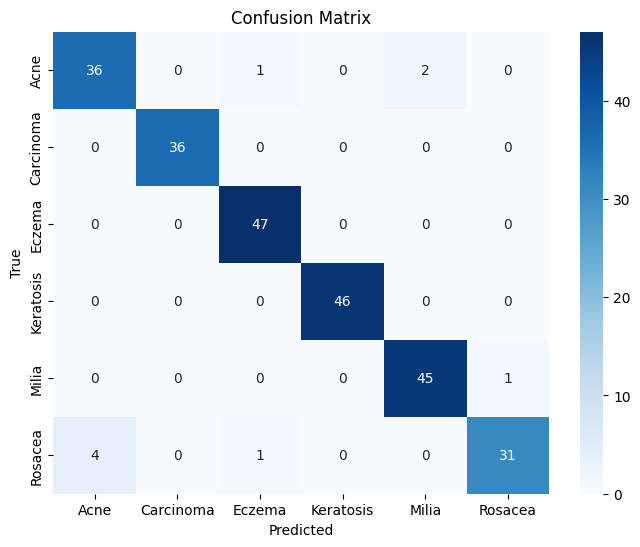


Confusion Matrix (Text Format):

               Acne  Carcinoma  Eczema  Keratosis  Milia  Rosacea
Acne               36       0       1       0       2       0
Carcinoma           0      36       0       0       0       0
Eczema              0       0      47       0       0       0
Keratosis           0       0       0      46       0       0
Milia               0       0       0       0      45       1
Rosacea             4       0       1       0       0      31


In [34]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix
from tensorflow.keras.applications.efficientnet_v2 import EfficientNetV2B0, preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
import os

# ===== 1. Dataset Loading =====
dataset_dir = '/kaggle/input/augmented-skin-conditions-image-dataset/Skin_Conditions'

# Load dataset
full_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_dir,
    image_size=(224, 224),
    label_mode='int',
    batch_size=32,
    shuffle=True
)

# ===== 2. Dataset Splitting =====
def split_dataset(dataset, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1):
    total_batches = tf.data.experimental.cardinality(dataset).numpy()
    train_batches = int(train_ratio * total_batches)
    val_batches = int(val_ratio * total_batches)

    train_ds = dataset.take(train_batches)
    val_ds = dataset.skip(train_batches).take(val_batches)
    test_ds = dataset.skip(train_batches + val_batches)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = split_dataset(full_dataset)

# ===== 3. Preprocessing =====
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))
test_ds = test_ds.map(lambda x, y: (preprocess_input(x), y))

# Improve performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# ===== 4. Class Names and Weights =====
class_names = full_dataset.class_names

# Get labels for class weight calculation
label_list = []
for _, label in full_dataset.unbatch():
    label_list.append(label.numpy())

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(label_list),
    y=label_list
)
class_weights_dict = dict(enumerate(class_weights))

# ===== 5. Model Definition (EfficientNetV2B0) =====
base_model = EfficientNetV2B0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base initially

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.4)(x)
output = Dense(len(class_names), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# ===== 6. Compile Model =====
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# ===== 7. Train Initial Layers =====
initial_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights_dict
)

# ===== 8. Fine-Tune Deeper Layers =====
base_model.trainable = True
for layer in base_model.layers[:-100]:
    layer.trainable = False

lr_schedule = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=3,
    verbose=1,
    min_lr=1e-6
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights_dict,
    callbacks=[lr_schedule]
)

# ===== 9. Final Evaluation =====
test_loss, test_acc = model.evaluate(test_ds)
print(f"\n✅ Final Test Accuracy: {test_acc:.4f}")

# ===== 10. Confusion Matrix =====
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Print confusion matrix textually
print("\nConfusion Matrix (Text Format):\n")
print(" " * 15 + "  ".join(class_names))
for i, row in enumerate(cm):
    print(f"{class_names[i]:<15}{'  '.join(f'{n:>6}' for n in row)}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


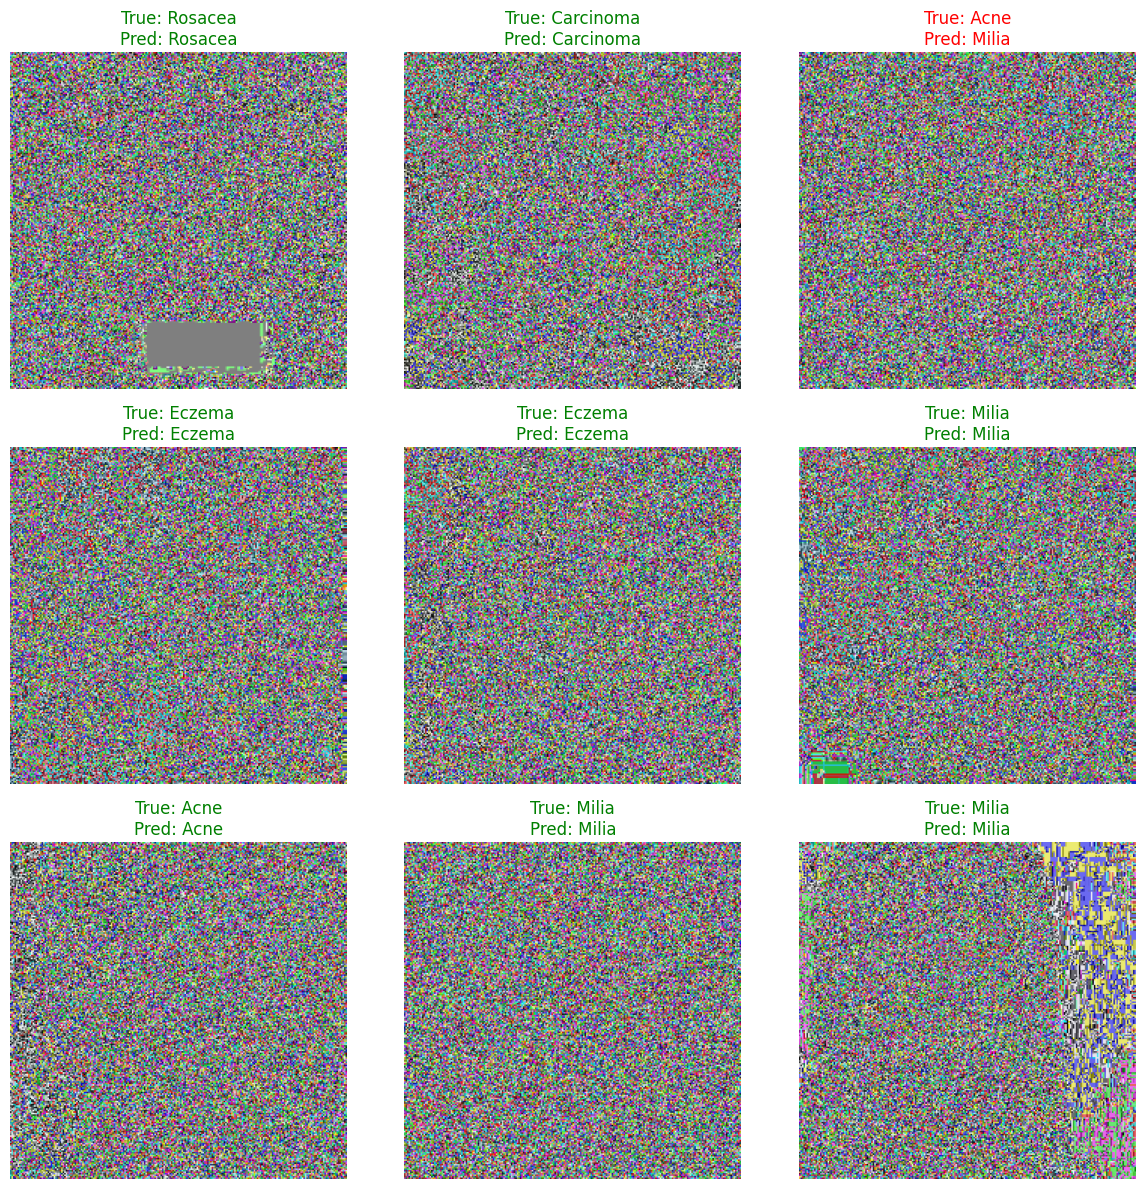

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import random

def show_random_predictions(model, dataset, class_names, num_images=9):
    plt.figure(figsize=(12, 12))
    dataset = dataset.unbatch().shuffle(1000)
    for i, (image, label) in enumerate(dataset.take(num_images)):
        ax = plt.subplot(3, 3, i + 1)
        img_array = tf.expand_dims(image, axis=0)  # add batch dimension
        prediction = model.predict(img_array)
        predicted_label = np.argmax(prediction)

        plt.imshow((image.numpy() * 127.5 + 127.5).astype("uint8"))  # undo normalization
        color = "green" if predicted_label == label else "red"
        plt.title(f"True: {class_names[label]}\nPred: {class_names[predicted_label]}", color=color)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# ✅ Call the function
show_random_predictions(model, test_ds, class_names)


In [38]:
model.save("skin_model.keras")

In [40]:
model.save("/kaggle/working/skin_model.keras")
model.save("/kaggle/working/skin_model.h5")

In [41]:
model.export("/kaggle/working/saved_skin_model")

Saved artifact at '/kaggle/working/saved_skin_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1074')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  136598887508528: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136598891626192: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136598891626016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136617341053312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136620771311680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136620782035088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136620776194288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136619869250384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136619869247216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136619869250912: TensorSpec(shape=(), dtype=t

In [42]:
import shutil
shutil.make_archive("/kaggle/working/saved_skin_model", 'zip', "/kaggle/working/saved_skin_model")

'/kaggle/working/saved_skin_model.zip'

In [43]:
loaded_model = tf.saved_model.load("/kaggle/working/saved_skin_model")

In [49]:
from huggingface_hub import logout
logout()  # Clear any old token

from huggingface_hub import login
login()  # Paste the correct token here (from https://huggingface.co/settings/tokens)

Successfully logged out.


In [52]:
from huggingface_hub import login
login(token="YOUR_HF_TOKEN")

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `huggingface-cli` if you want to set the git credential as well.
Token is valid (permission: fineGrained).
Your token has been saved to /root/.cache/huggingface/token
Login successful


In [54]:
from huggingface_hub import HfApi
import os

# Optional: directly use your token here instead of os.getenv
HF_TOKEN = "YOUR_HF_TOKEN"

api = HfApi(token=HF_TOKEN)

api.upload_folder(
    folder_path="/kaggle/working/saved_skin_model",   
    repo_id="Tanishq77/skin-condition-classifier",
    repo_type="model"
)


fingerprint.pb:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

variables.data-00000-of-00001:   0%|          | 0.00/52.7M [00:00<?, ?B/s]

Upload 3 LFS files:   0%|          | 0/3 [00:00<?, ?it/s]

saved_model.pb:   0%|          | 0.00/2.62M [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/Tanishq77/skin-condition-classifier/commit/3638d0ae4cf676f5f7176ef51f866029b9c6ec8e', commit_message='Upload folder using huggingface_hub', commit_description='', oid='3638d0ae4cf676f5f7176ef51f866029b9c6ec8e', pr_url=None, pr_revision=None, pr_num=None)